In [1]:
# --- Setup: make the project root importable ---
import sys
from pathlib import Path

# The notebook runs from notebooks/, so the project root is one level up
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.append(str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_raw, add_target
from src.config import TARGET_COL, FIGURES_DIR

sns.set_theme(style="whitegrid")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)  # make sure the folder exists

df = add_target(load_raw("por"))
print("Shape:", df.shape)
df.head()

Shape: (649, 34)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,fail
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,4,0,11,11,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,2,9,11,11,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,6,12,13,12,0
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,0,14,14,14,0
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,0,11,13,13,0


In [2]:
# --- Class imbalance: counts and percentages ---
counts = df[TARGET_COL].value_counts().sort_index()          # 0 = pass, 1 = fail
pct = df[TARGET_COL].value_counts(normalize=True).sort_index() * 100

print(f"Pass (0): {counts[0]} students ({pct[0]:.1f}%)")
print(f"Fail (1): {counts[1]} students ({pct[1]:.1f}%)")

# A "dumb" model that always predicts the majority class (Pass)
baseline_acc = pct.max()
print(f"\nAlways-predict-Pass accuracy: {baseline_acc:.1f}%")
print("→ Any model must clearly beat this, and accuracy alone can't show it.")

Pass (0): 549 students (84.6%)
Fail (1): 100 students (15.4%)

Always-predict-Pass accuracy: 84.6%
→ Any model must clearly beat this, and accuracy alone can't show it.


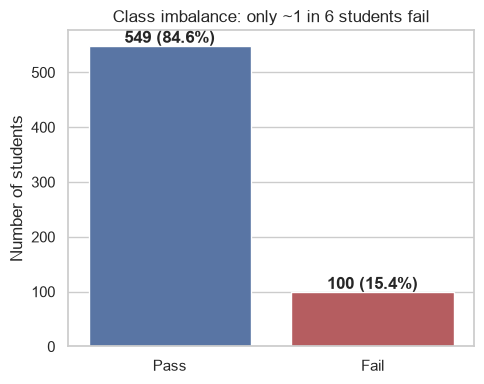

In [3]:
# --- Bar chart of the class balance ---
fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=["Pass", "Fail"], y=counts.values, ax=ax,
            hue=["Pass", "Fail"], palette=["#4C72B0", "#C44E52"], legend=False)
for i, v in enumerate(counts.values):
    ax.text(i, v + 5, f"{v} ({pct.iloc[i]:.1f}%)", ha="center", fontweight="bold")

ax.set_title("Class imbalance: only ~1 in 6 students fail")
ax.set_ylabel("Number of students")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_class_imbalance.png", dpi=150)
plt.show()